# Predictor & Target Diagnostics

This notebook builds the modeling population once, at the top, and reuses it across every
section below -- rather than reloading and reprocessing it separately each time. The population is built via `target_construction`'s
`load_model_base` -> `remove_young_loans` -> `remove_cancelled_and_committed` -> `assign_target`,
with the same arguments throughout.


**What this notebook is asking.** Different from Notebooks 1 & 2 -- this one runs on the actual
seasoned, modeling-ready population (`target_60mo`, not the raw resolved-basis rate used above),
right before WOE/IV binning. The question here isn't "is there a pattern" but "is this population
safe to model": are any two predictors redundant, do distributions have a sane shape to bin, and --
the one that actually caught a bug before -- does every category that will appear at test time also
appear in training?

In [1]:
import sys
from pathlib import Path

def _find_project_root(marker="sector_eda.py"):
    """Walk up from the current working directory until we find the repo
    root (identified by sector_eda.py sitting next to src/) -- more robust
    than assuming cwd is any particular folder name, which breaks silently
    depending on how Jupyter was launched (plain `jupyter lab`, VS Code, etc.)."""
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / marker).exists() and (candidate / "src").is_dir():
            return candidate
    raise FileNotFoundError(
        f"Could not locate the project root (looked for {marker!r} above {here}). "
        "Run this notebook from somewhere inside the pd-model-sba repo."
    )

PROJECT_ROOT = _find_project_root()
sys.path.insert(0, str(PROJECT_ROOT / "src" / "features"))
# the module being imported below already inserts the repo root itself
# on import (for its own `from sector_eda import ...`), so nothing further to add here.
from target_construction import (
    load_model_base, remove_young_loans, remove_cancelled_and_committed, assign_target,
)

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
%matplotlib inline

OUT = str(PROJECT_ROOT / "outputs" / "figures" / "pd_model")
OUT_ROOT_FIGS = str(PROJECT_ROOT / "outputs" / "figures")
Path(OUT).mkdir(parents=True, exist_ok=True)

raw = load_model_base()
df = remove_young_loans(raw, n_months=60)
df = remove_cancelled_and_committed(df)
df = assign_target(df, n_months=60)
print(f"modeling population: {len(df)} rows, defaults (target_60mo==1): {(df['target_60mo']==1).sum()}")

FranchiseCode: nunique changed 5074 -> 5025 after whitespace/case normalization (hidden duplicate categories collapsed)
FranchiseCode: nunique changed 3691 -> 3598 after whitespace/case normalization (hidden duplicate categories collapsed)
modeling population: 543123 rows, defaults (target_60mo==1): 20431


## Continuous predictor correlations
Correlation check across the continuous predictors, on the modeling population. Run before
binning to catch redundant pairs (e.g. loan amount vs. guaranteed amount, which are structurally
related -- guarantee is a % of approval) before they're both fed into the model.

correlation matrix, continuous predictors:
                       GrossApproval  SBAGuaranteedApproval  InitialInterestRate  TermInMonths  JobsSupported
GrossApproval                   1.00                   1.00                -0.25          0.51           0.29
SBAGuaranteedApproval           1.00                   1.00                -0.25          0.51           0.29
InitialInterestRate            -0.25                  -0.25                 1.00         -0.23          -0.14
TermInMonths                    0.51                   0.51                -0.23          1.00           0.07
JobsSupported                   0.29                   0.29                -0.14          0.07           1.00

pairs with |correlation| >= 0.5 (worth a closer look):
  GrossApproval x SBAGuaranteedApproval: r=1.00
  GrossApproval x TermInMonths: r=0.51
  SBAGuaranteedApproval x TermInMonths: r=0.51


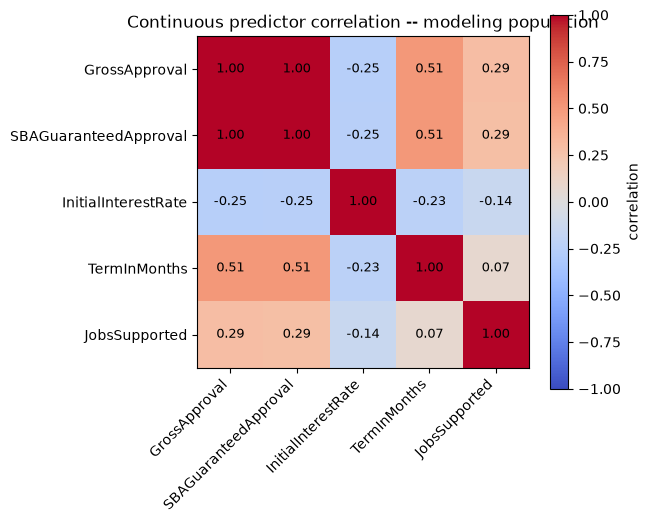

saved /Users/yk/YK/2026/Python/PD_related/PD_project/pd-model-sba/outputs/figures/pd_model/03_predictor_correlation_heatmap.png


In [2]:
CONTINUOUS_VARS = ["GrossApproval", "SBAGuaranteedApproval", "InitialInterestRate",
                    "TermInMonths", "JobsSupported"]

corr = df[CONTINUOUS_VARS].corr()
print("correlation matrix, continuous predictors:")
print(corr.round(2).to_string())

print("\npairs with |correlation| >= 0.5 (worth a closer look):")
for i, a in enumerate(CONTINUOUS_VARS):
    for b in CONTINUOUS_VARS[i + 1:]:
        r = corr.loc[a, b]
        if abs(r) >= 0.5:
            print(f"  {a} x {b}: r={r:.2f}")

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(CONTINUOUS_VARS)))
ax.set_yticks(range(len(CONTINUOUS_VARS)))
ax.set_xticklabels(CONTINUOUS_VARS, rotation=45, ha="right")
ax.set_yticklabels(CONTINUOUS_VARS)
for i in range(len(CONTINUOUS_VARS)):
    for j in range(len(CONTINUOUS_VARS)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, label="correlation")
ax.set_title("Continuous predictor correlation -- modeling population")
fig.tight_layout()
fig.savefig(f"{OUT}/03_predictor_correlation_heatmap.png", dpi=150)
plt.show()
print(f"saved {OUT}/03_predictor_correlation_heatmap.png")

## Predictor distributions
Distribution histograms for the continuous predictors, on the actual modeling population. Purely
diagnostic -- run before WOE/IV binning to see each variable's shape and decide where natural
split points might be.

In [3]:
HIST_VARS = {
    "GrossApproval": "Loan amount approved ($)",
    "SBAGuaranteedApproval": "SBA-guaranteed amount ($)",
    "InitialInterestRate": "Interest rate at origination (%)",
    "TermInMonths": "Loan term (months)",
    "JobsSupported": "Jobs supported (count)",
}

print("continuous predictor summary (modeling population):")
print(df[list(HIST_VARS)].describe().to_string())
print()
print("missing %:")
print((df[list(HIST_VARS)].isna().mean() * 100).round(2).to_string())

continuous predictor summary (modeling population):
       GrossApproval  SBAGuaranteedApproval  InitialInterestRate   TermInMonths  JobsSupported
count   5.431230e+05           5.431230e+05        543123.000000  543123.000000  543123.000000
mean    4.007412e+05           2.998152e+05             6.487426     123.825610      10.735318
std     7.036065e+05           5.448278e+05             1.567783      80.149089      20.361427
min     1.000000e+03           5.000000e+02             0.000000       0.000000       0.000000
25%     4.500000e+04           2.500000e+04             5.500000      84.000000       2.000000
50%     1.420000e+05           9.180000e+04             6.000000      96.000000       5.000000
75%     4.000000e+05           3.000000e+05             7.250000     120.000000      12.000000
max     5.000000e+06           4.500000e+06            15.240000     432.000000    2150.000000

missing %:
GrossApproval            0.0
SBAGuaranteedApproval    0.0
InitialInterestRate    

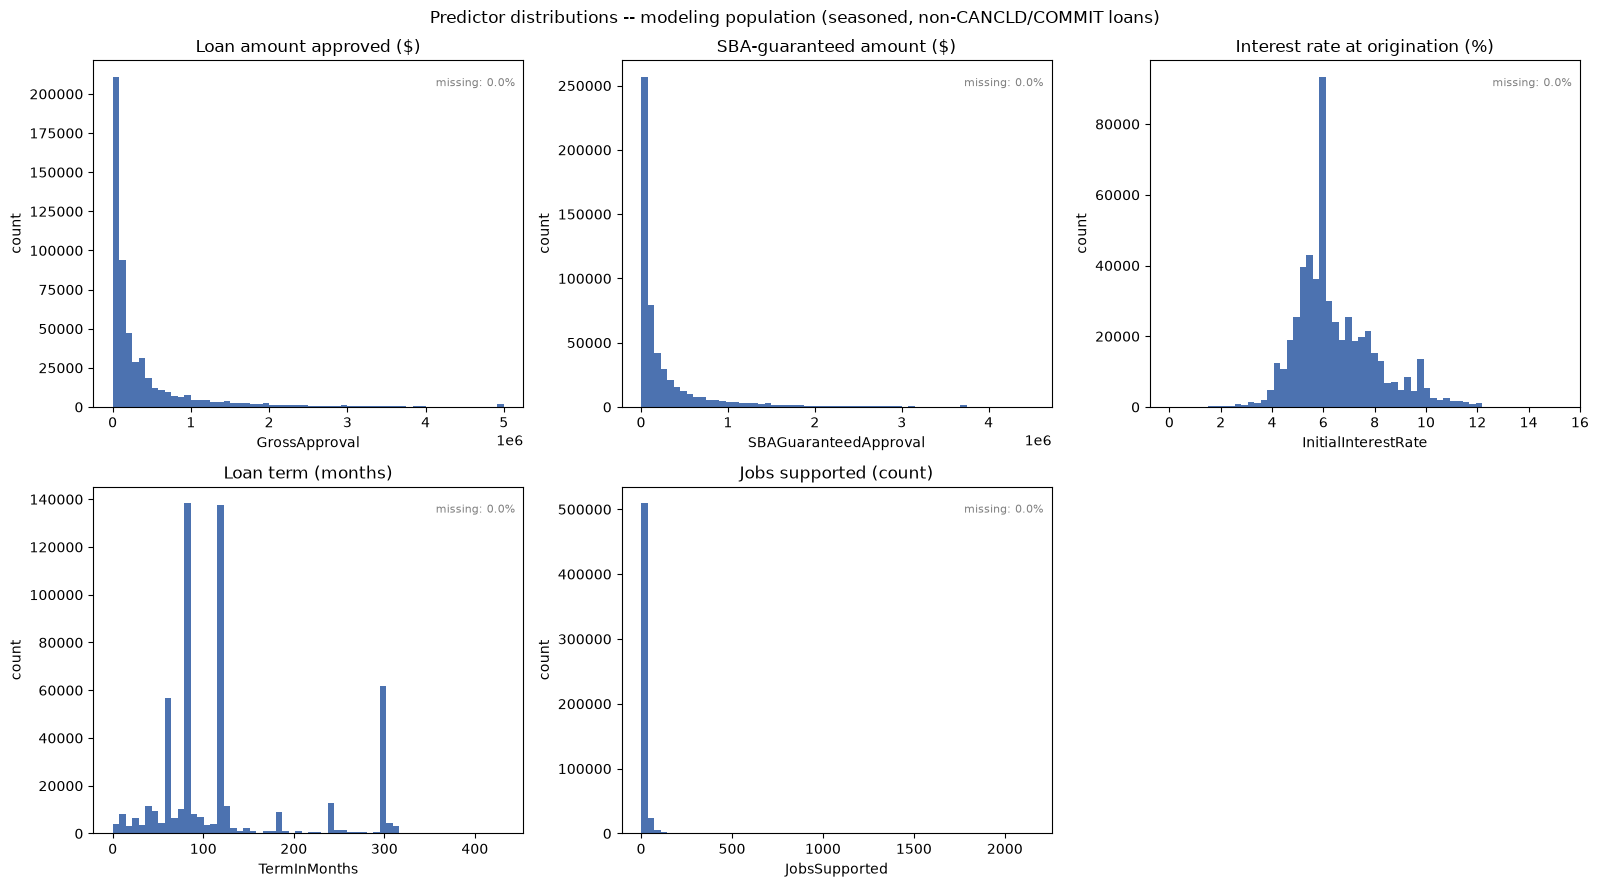

saved /Users/yk/YK/2026/Python/PD_related/PD_project/pd-model-sba/outputs/figures/pd_model/02_predictor_distributions.png


In [4]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
for ax, (col, label) in zip(axes, HIST_VARS.items()):
    vals = df[col].dropna()
    ax.hist(vals, bins=60, color="#4C72B0", edgecolor="none")
    ax.set_title(label)
    ax.set_xlabel(col)
    ax.set_ylabel("count")
    n_missing = df[col].isna().sum()
    pct_missing = 100 * n_missing / len(df)
    ax.text(0.98, 0.95, f"missing: {pct_missing:.1f}%", transform=ax.transAxes,
            ha="right", va="top", fontsize=8, color="gray")
for ax in axes[len(HIST_VARS):]:
    ax.axis("off")
fig.suptitle("Predictor distributions -- modeling population (seasoned, non-CANCLD/COMMIT loans)")
fig.tight_layout()
fig.savefig(f"{OUT}/02_predictor_distributions.png", dpi=150)
plt.show()
print(f"saved {OUT}/02_predictor_distributions.png")

## Predictor scatterplots
Scatterplots between continuous predictors -- the visual complement to the correlation heatmap
above. A single correlation number can hide the actual shape of a relationship (discrete
clustering, tiered/step patterns, curvature).

Sampled, not the full population: at full volume a plain scatter is just an overplotted blob.
`SAMPLE_N` points are drawn at random (fixed seed, reproducible) -- large enough to show the real
shape, small enough to stay readable.

modeling population: 543123 rows, sampled 8000 for plotting (seed=42)


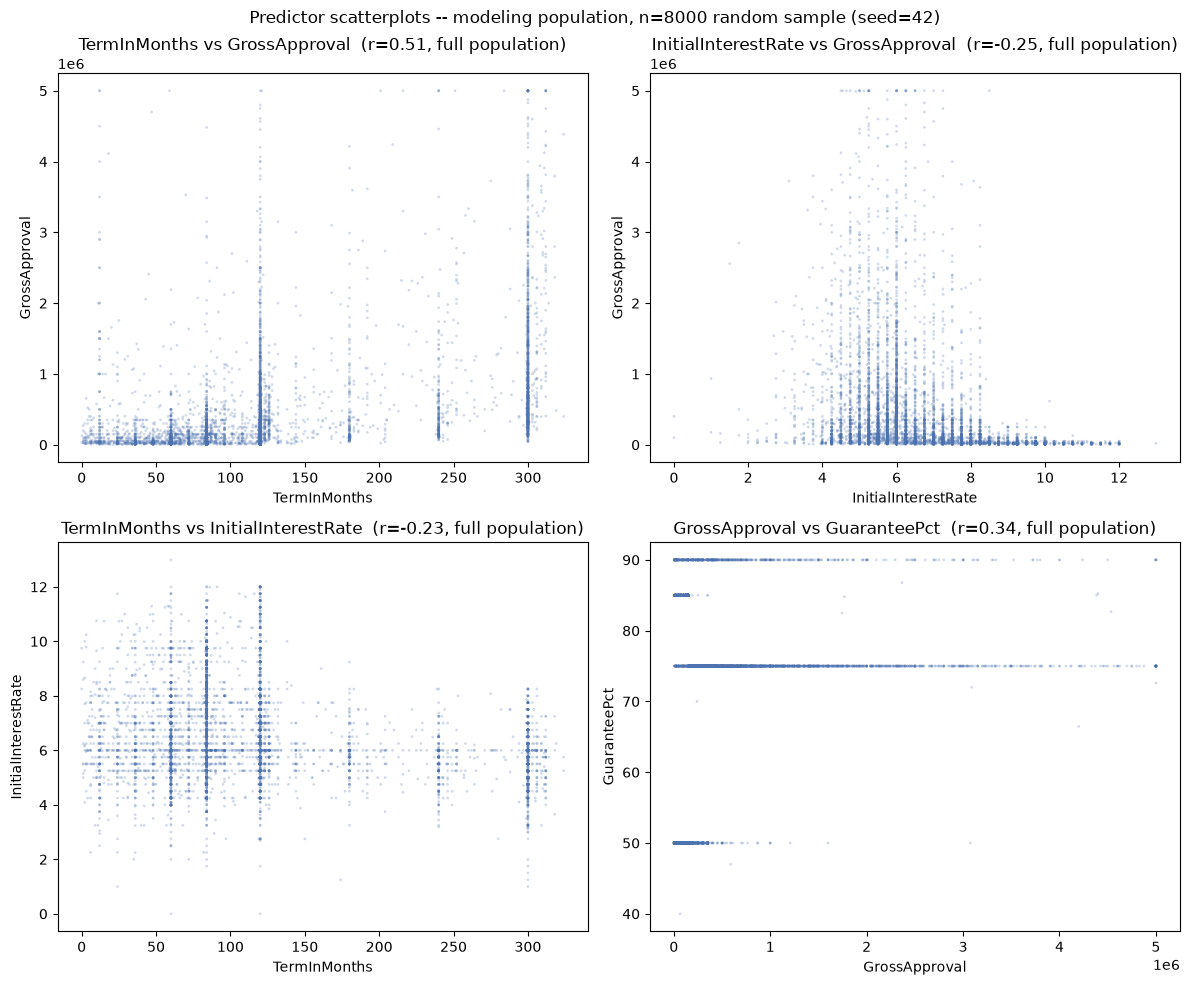

saved /Users/yk/YK/2026/Python/PD_related/PD_project/pd-model-sba/outputs/figures/pd_model/06_predictor_scatterplots.png


In [5]:
SAMPLE_N = 8000
SCATTER_SEED = 42
PAIRS = [
    ("TermInMonths", "GrossApproval"),
    ("InitialInterestRate", "GrossApproval"),
    ("TermInMonths", "InitialInterestRate"),
    ("GrossApproval", "GuaranteePct"),
]

df["GuaranteePct"] = df["SBAGuaranteedApproval"] / df["GrossApproval"] * 100
sample = df.sample(n=SAMPLE_N, random_state=SCATTER_SEED)
print(f"modeling population: {len(df)} rows, sampled {SAMPLE_N} for plotting (seed={SCATTER_SEED})")

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()
for ax, (x, y) in zip(axes, PAIRS):
    ax.scatter(sample[x], sample[y], s=4, alpha=0.25, color="#4C72B0", edgecolors="none")
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    r = df[[x, y]].corr().iloc[0, 1]
    ax.set_title(f"{x} vs {y}  (r={r:.2f}, full population)")
fig.suptitle(f"Predictor scatterplots -- modeling population, n={SAMPLE_N} random sample (seed={SCATTER_SEED})")
fig.tight_layout()
fig.savefig(f"{OUT}/06_predictor_scatterplots.png", dpi=150)
plt.show()
print(f"saved {OUT}/06_predictor_scatterplots.png")

## ProcessingMethod x ApprovalFY coverage
Which loan programs existed in which years. Built retroactively, after an XGBoost run crashed on
a `ProcessingMethod` category the training years never saw (COMMUNITYADVANTAGERECOVERYLOAN,
SBAEXPRESSBRIDGELOAN -- both introduced after 2018). A crosstab like this, built during EDA, would
have caught the train/test category mismatch before it ever became a modeling bug -- SBA loan
programs get introduced and discontinued over time, same as any other categorical field with a
time dimension.

ProcessingMethod x ApprovalFY loan counts:
ApprovalFY                             2010   2011   2012   2013   2014   2015   2016   2017   2018   2019   2020   2021
ProcessingMethod                                                                                                        
SBAEXPRESSPROGRAM                     16868  22565  20030  18786  23425  28457  28558  26419  24941  20040  15504  10053
PREFERREDLENDERSPROGRAM               10563  12451  10823  11498  11031  14188  15458  22550  23712  20976  16858  14931
7AGENERAL                              4893   5497   3973   3368   2805   3152   3249   3762   3775   3241   3089   2341
SMALLLOANADVANTAGEINITIATIVE              0    110    714   3520   6682   7639   7511   1466      0      0      0      0
COMMUNITYADVANTAGEINITIATIVE              0     12    154    232    385    721    843    902    999    775    431    347
PATRIOTEXPRESSLOANS                    1873   1380   1056    960    282      0      0      0      0      0    

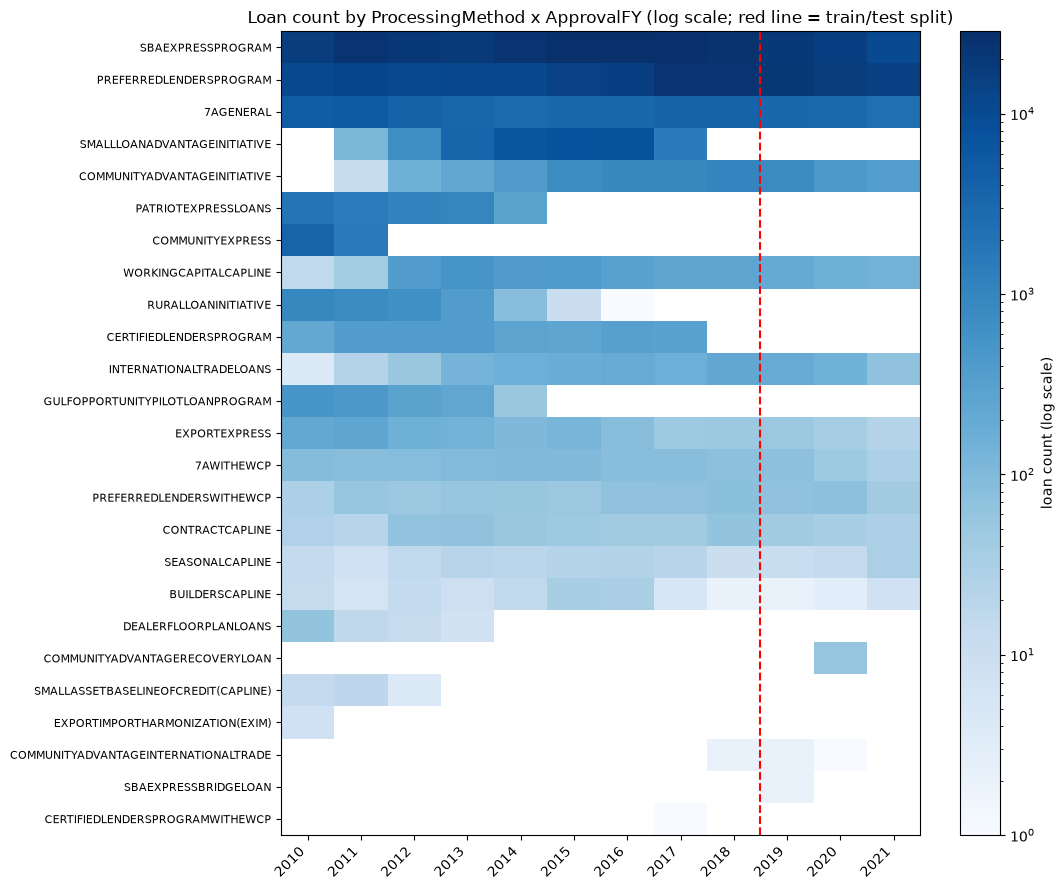

saved /Users/yk/YK/2026/Python/PD_related/PD_project/pd-model-sba/outputs/figures/37_processingmethod_by_year_coverage.png


In [6]:
counts = df.groupby(["ProcessingMethod", "ApprovalFY"], observed=True).size().unstack(fill_value=0)
counts = counts.loc[counts.sum(axis=1).sort_values(ascending=False).index]

print("ProcessingMethod x ApprovalFY loan counts:")
print(counts.to_string())

print("\nmethods present in 2019-2021 but not 2010-2018 (or vice versa):")
train_years = [c for c in counts.columns if c <= 2018]
test_years = [c for c in counts.columns if c > 2018]
train_only = counts[(counts[train_years].sum(axis=1) > 0) & (counts[test_years].sum(axis=1) == 0)]
test_only = counts[(counts[train_years].sum(axis=1) == 0) & (counts[test_years].sum(axis=1) > 0)]
print(f"train-only (discontinued before 2019): {list(train_only.index)}")
print(f"test-only (introduced after 2018): {list(test_only.index)}")

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(counts.values, aspect="auto", cmap="Blues",
                norm=matplotlib.colors.LogNorm(vmin=1, vmax=counts.values.max()))
ax.set_xticks(range(len(counts.columns)))
ax.set_xticklabels(counts.columns, rotation=45, ha="right")
ax.set_yticks(range(len(counts.index)))
ax.set_yticklabels(counts.index, fontsize=8)
ax.axvline(x=train_years[-1] - counts.columns[0] + 0.5, color="red", linewidth=1.5, linestyle="--")
ax.set_title("Loan count by ProcessingMethod x ApprovalFY (log scale; red line = train/test split)")
fig.colorbar(im, label="loan count (log scale)")
fig.tight_layout()
fig.savefig(f"{OUT_ROOT_FIGS}/37_processingmethod_by_year_coverage.png", dpi=150)
plt.show()
print(f"saved {OUT_ROOT_FIGS}/37_processingmethod_by_year_coverage.png")

## Where do defaults cluster in feature-space?
`GrossApproval` x `InitialInterestRate`, drawn as density contours (defaulted vs. not) instead of
individual points -- shows where each group concentrates without needing to sample, true
proportions preserved.

A matched-sample scatter version (all defaults + an equal-sized random sample of non-defaults) was
tried first and dropped: credit risk is inherently time-dependent, and a random sample flattens
that away, so it added a cross-sectional view without much real diagnostic value once this density
version already covers the same question more rigorously (true proportions, no sampling choice to
defend).

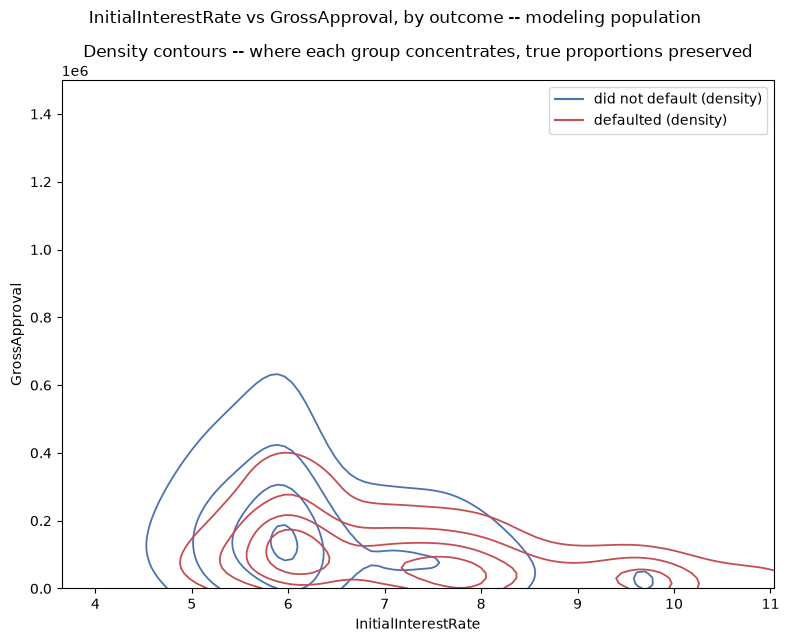

saved /Users/yk/YK/2026/Python/PD_related/PD_project/pd-model-sba/outputs/figures/pd_model/07_default_pattern_density.png


In [7]:
DENSITY_SEED = 42
X_COL, Y_COL = "InitialInterestRate", "GrossApproval"

defaults = df[df["target_60mo"] == 1][[X_COL, Y_COL]].dropna()
non_defaults = df[df["target_60mo"] == 0][[X_COL, Y_COL]].dropna().sample(n=20000, random_state=DENSITY_SEED)

xmin, xmax = df[X_COL].quantile([0.01, 0.99])
ymin, ymax = 0, 1_500_000
xx, yy = np.mgrid[xmin:xmax:100j, ymin:ymax:100j]
grid = np.vstack([xx.ravel(), yy.ravel()])

fig, ax = plt.subplots(figsize=(8, 6.5))
for data, color, label in [(non_defaults, "#4C72B0", "did not default"),
                            (defaults, "#C44E52", "defaulted")]:
    kde = gaussian_kde(data.T.values)
    zz = kde(grid).reshape(xx.shape)
    ax.contour(xx, yy, zz, levels=5, colors=color, linewidths=1.3)
ax.plot([], [], color="#4C72B0", label="did not default (density)")
ax.plot([], [], color="#C44E52", label="defaulted (density)")
ax.set_xlabel(X_COL)
ax.set_ylabel(Y_COL)
ax.set_ylim(ymin, ymax)
ax.set_title("Density contours -- where each group concentrates, true proportions preserved")
ax.legend()
fig.suptitle(f"{X_COL} vs {Y_COL}, by outcome -- modeling population")
fig.tight_layout()
fig.savefig(f"{OUT}/07_default_pattern_density.png", dpi=150)
plt.show()
print(f"saved {OUT}/07_default_pattern_density.png")

## What this notebook tells us

- **No dangerously redundant predictor pairs** at the |r| >= 0.5 threshold checked here (see the
  correlation matrix) -- safe to bin all five continuous predictors independently.
- **Distributions are usable but not clean** -- several predictors show the tiered/step patterns
  called out in the scatterplot section, which is part of why this project's binning is
  z-test-driven rather than fixed-cutpoint.
- **Where defaults cluster** (the density-contour section) shows defaults concentrate at higher
  rate and lower loan size, not a surprise but a useful sanity check before trusting the model's
  learned coefficients later.
- **The real catch:** `ProcessingMethod` coverage is NOT stable across the train/test split --
  some programs (COMMUNITYADVANTAGERECOVERYLOAN, SBAEXPRESSBRIDGELOAN) only exist after 2018 and
  were never seen in training. This is the exact gap that crashed an earlier XGBoost run --
  confirmed here, not just asserted, before modeling continues.